# SDG Country Analysis — SDR 2026

In [1]:
%pip install -q pandas numpy openpyxl plotly

Note: you may need to restart the kernel to use updated packages.


C:\Users\KIIT0001\AppData\Local\Programs\Python\Python314\python.exe: No module named pip


In [3]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import plotly.express as px
from IPython.display import display

FILE = Path("database_2026.xlsx")
if not FILE.exists():
    raise FileNotFoundError(f"Place database_2026.xlsx in this folder: {Path.cwd()}")

xls = pd.ExcelFile(FILE)
print("Sheets:", xls.sheet_names)

Sheets: ['About', 'Overview', 'Codebook', 'SDR2026 Data', 'All Raw Data', 'Backdated SDG Index', 'Backdated - Ranks over time']


In [4]:
overview = pd.read_excel(FILE, sheet_name="Overview")
sdr = pd.read_excel(FILE, sheet_name="SDR2026 Data")
raw = pd.read_excel(FILE, sheet_name="All Raw Data")
backdated = pd.read_excel(FILE, sheet_name="Backdated SDG Index")
ranks = pd.read_excel(FILE, sheet_name="Backdated - Ranks over time")
codebook = pd.read_excel(FILE, sheet_name="Codebook")

for df in [overview, sdr, raw, backdated, ranks, codebook]:
    df.columns = [str(c).strip() for c in df.columns]

raw["country"] = raw["country"].astype(str).str.strip()
raw["year"] = pd.to_numeric(raw["year"], errors="coerce")
raw = raw.dropna(subset=["country", "year"]).copy()
raw["year"] = raw["year"].astype(int)
backdated["country"] = backdated["country"].astype(str).str.strip()
backdated["year"] = pd.to_numeric(backdated["year"], errors="coerce")
backdated = backdated.dropna(subset=["country", "year"]).copy()
backdated["year"] = backdated["year"].astype(int)

print("Overview:", overview.shape)
print("Country indicator rows:", raw.shape)
print("Backdated index rows:", backdated.shape)
print("Countries in raw data:", raw["country"].nunique())
print("Year range:", raw["year"].min(), "to", raw["year"].max())
display(overview.head())
display(codebook[["IndCode", "SDG", "Indicator"]].head())

Overview: (208, 39)
Country indicator rows: (5616, 128)
Backdated index rows: (4758, 123)
Countries in raw data: 208
Year range: 2000 to 2026


,country,2026 SDG Index Score,2026 SDG Index Rank,International Spillovers Score (0-100),Regions used for the SDR,Goal 1 Dash,Goal 1 Trend,Goal 2 Dash,Goal 2 Trend,Goal 3 Dash,...,Goal 13 Dash,Goal 13 Trend,Goal 14 Dash,Goal 14 Trend,Goal 15 Dash,Goal 15 Trend,Goal 16 Dash,Goal 16 Trend,Goal 17 Dash,Goal 17 Trend
0,Finland,87.404948,1.0,66.877231,OECD,green,→,orange,→,yellow,...,red,➚,orange,➚,orange,→,yellow,➚,orange,➚
1,Sweden,86.263311,2.0,62.453462,OECD,green,↑,orange,→,yellow,...,orange,→,red,→,red,→,orange,→,yellow,➚
2,Denmark,85.678241,3.0,58.768846,OECD,green,→,orange,→,yellow,...,red,➚,orange,→,orange,➚,yellow,➚,yellow,➚
3,Norway,84.080874,4.0,56.985615,OECD,green,↑,orange,→,green,...,red,➚,orange,→,red,➚,orange,➚,orange,→
4,Germany,84.021482,5.0,63.265462,OECD,yellow,↓,orange,➚,orange,...,red,➚,orange,➚,yellow,→,yellow,→,orange,→


,IndCode,SDG,Indicator
0,sdg1_wpc,1,Poverty headcount ratio at $3.00/day (%)
1,sdg1_lmicpov,1,Poverty headcount ratio at $4.20/day (%)
2,sdg1_oecdpov,1,Poverty rate after taxes and transfers (%)
3,sdg2_undernsh,2,Prevalence of undernourishment (%)
4,sdg2_stunting,2,Prevalence of stunting in children under 5 yea...


## 1. Clean and export reusable datasets

In [5]:
OUT = Path("clean_data")
OUT.mkdir(exist_ok=True)
overview.to_csv(OUT / "country_overview.csv", index=False)
sdr.to_csv(OUT / "sdr_2026_country_data.csv", index=False)
raw.to_csv(OUT / "all_raw_data_cleaned.csv", index=False)
backdated.to_csv(OUT / "backdated_sdg_index_cleaned.csv", index=False)
ranks.to_csv(OUT / "country_ranks_over_time.csv", index=False)
codebook.to_csv(OUT / "indicator_codebook.csv", index=False)
print("Saved cleaned CSV files to:", OUT.resolve())

Saved cleaned CSV files to: C:\Users\KIIT0001\OneDrive\Desktop\new\clean_data


## 2. Country score distribution and top countries

count    184.000000
mean      67.979012
std       10.329464
min       39.869153
25%       61.213122
50%       69.146021
75%       75.356935
max       87.404948
Name: 2026 SDG Index Score, dtype: float64


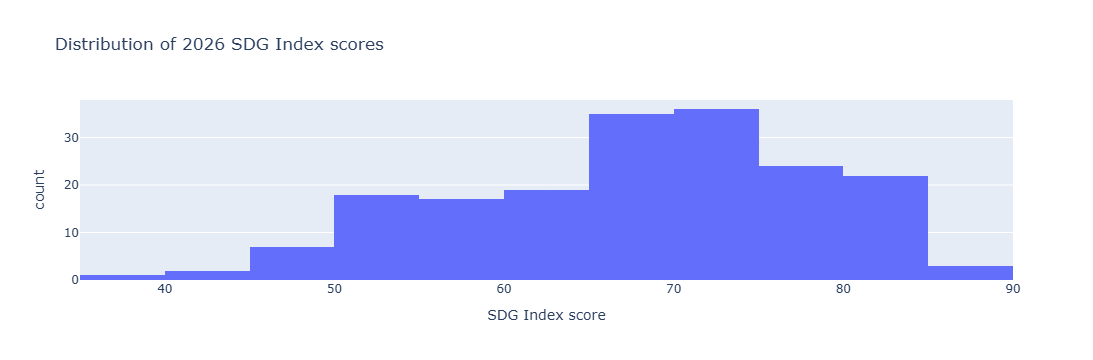

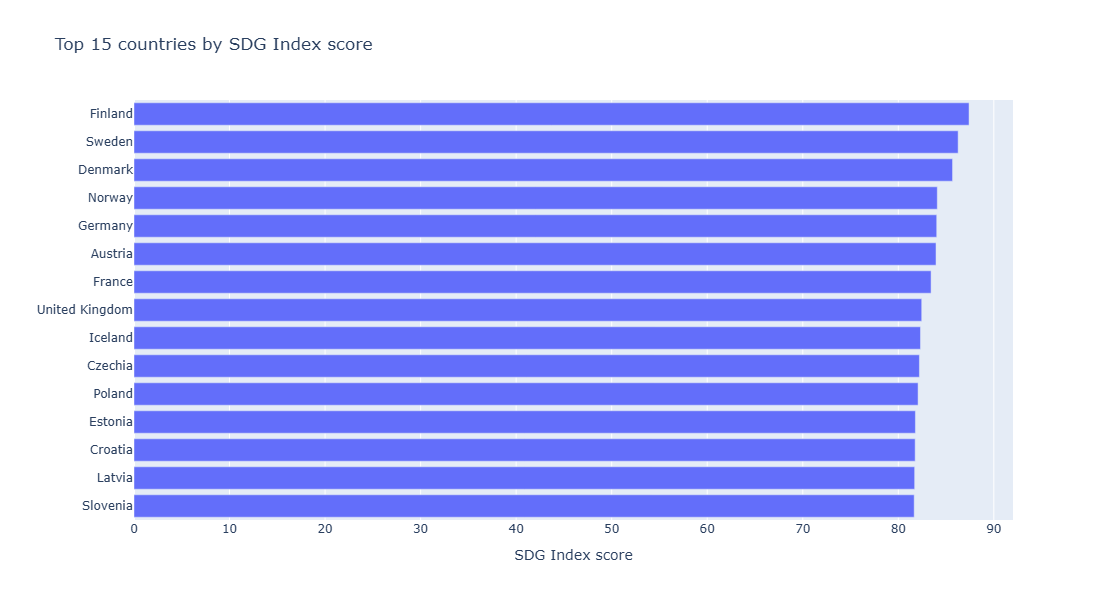

In [6]:
score_col = "2026 SDG Index Score"
rank_col = "2026 SDG Index Rank"
score_data = overview.dropna(subset=[score_col]).copy()
print(score_data[score_col].describe())
fig = px.histogram(score_data, x=score_col, nbins=20, title="Distribution of 2026 SDG Index scores",
                   labels={score_col: "SDG Index score"})
fig.show()

top = score_data.sort_values(score_col, ascending=False).head(15)
fig = px.bar(top.sort_values(score_col), x=score_col, y="country", orientation="h",
             title="Top 15 countries by SDG Index score",
             labels={score_col: "SDG Index score", "country": "Country"})
fig.update_layout(height=600, yaxis_title="")
fig.show()

## 3. Score vs international spillovers

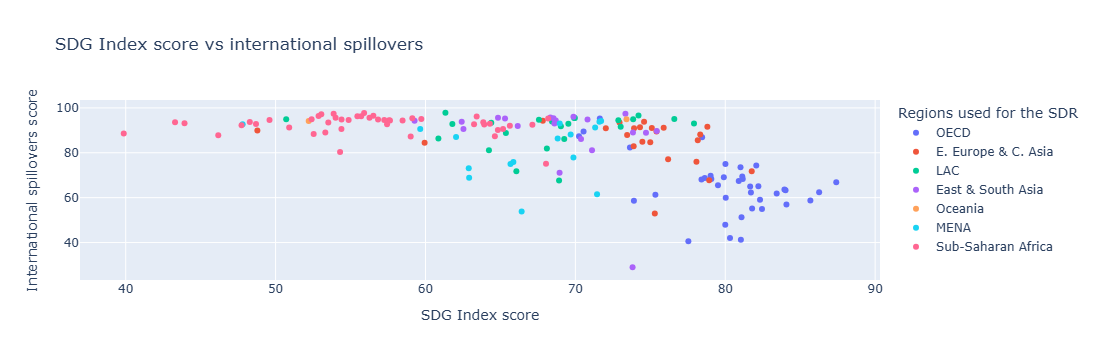

Pearson correlation: -0.5860108274664034


In [7]:
spill = "International Spillovers Score (0-100)"
fig = px.scatter(score_data.dropna(subset=[spill]), x=score_col, y=spill,
                 color="Regions used for the SDR", hover_name="country",
                 title="SDG Index score vs international spillovers",
                 labels={score_col: "SDG Index score", spill: "International spillovers score"})
fig.show()
print("Pearson correlation:", score_data[[score_col, spill]].corr().iloc[0,1])

## 4. Historical index trend

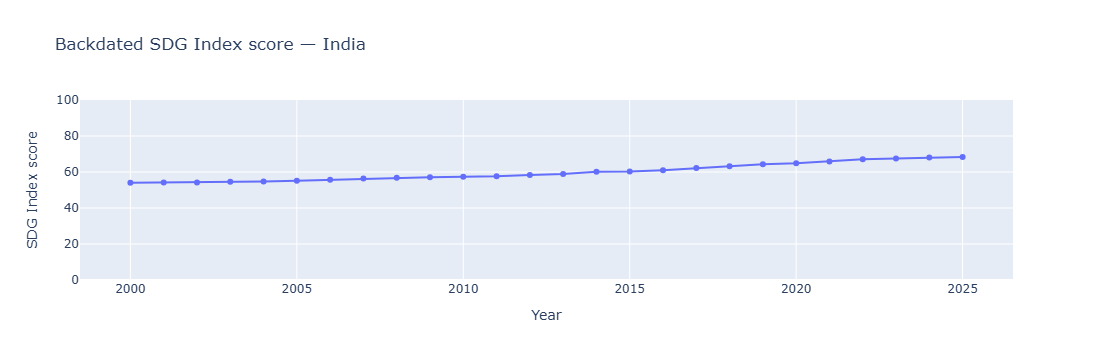

,id,country,year,indexreg_,sdgi_s,n_sdg1_wpc,n_sdg1_lmicpov,n_sdg2_undernsh,n_sdg2_stunting,n_sdg2_wasting,...,goal8,goal9,goal10,goal11,goal12,goal13,goal14,goal15,goal16,goal17
1846,IND,India,2000,E_S_Asia,54.083219,31.497,0.0,60.804,0.0,0.0,...,56.2880,33.706556,95.937,56.35375,87.590000,98.205333,53.527167,48.0116,49.3206,58.819333
1847,IND,India,2001,E_S_Asia,54.153218,33.506,0.0,60.804,0.0,0.0,...,56.2708,33.662000,95.937,55.53850,87.591429,98.193333,53.867167,47.9616,49.3842,58.417667
1848,IND,India,2002,E_S_Asia,54.127986,34.037,0.0,56.784,0.0,0.0,...,56.2158,33.661889,95.937,55.68325,87.848000,98.129333,53.364667,47.9116,49.4214,58.680833
1849,IND,India,2003,E_S_Asia,54.574976,36.131,0.0,53.015,0.0,0.0,...,56.2534,33.677444,95.937,54.93000,87.765857,98.133667,54.815000,47.9116,49.4744,58.011500
1850,IND,India,2004,E_S_Asia,54.684726,37.920,0.0,51.759,0.0,0.0,...,56.2810,34.399556,95.937,54.61000,87.359857,97.999000,54.005833,47.8616,49.4426,57.805833


In [8]:
backdated["sdgi_s"] = pd.to_numeric(backdated["sdgi_s"], errors="coerce")
country = "India"  # Change to any country in backdated['country'].unique()
hist = backdated.loc[backdated["country"].eq(country)].dropna(subset=["sdgi_s"]).sort_values("year")
if hist.empty:
    print("No index history for", country)
else:
    fig = px.line(hist, x="year", y="sdgi_s", markers=True,
                  title=f"Backdated SDG Index score — {country}",
                  labels={"year": "Year", "sdgi_s": "SDG Index score"})
    fig.update_yaxes(range=[0, 100])
    fig.show()
display(hist.head())

## 5. Missingness in raw indicators

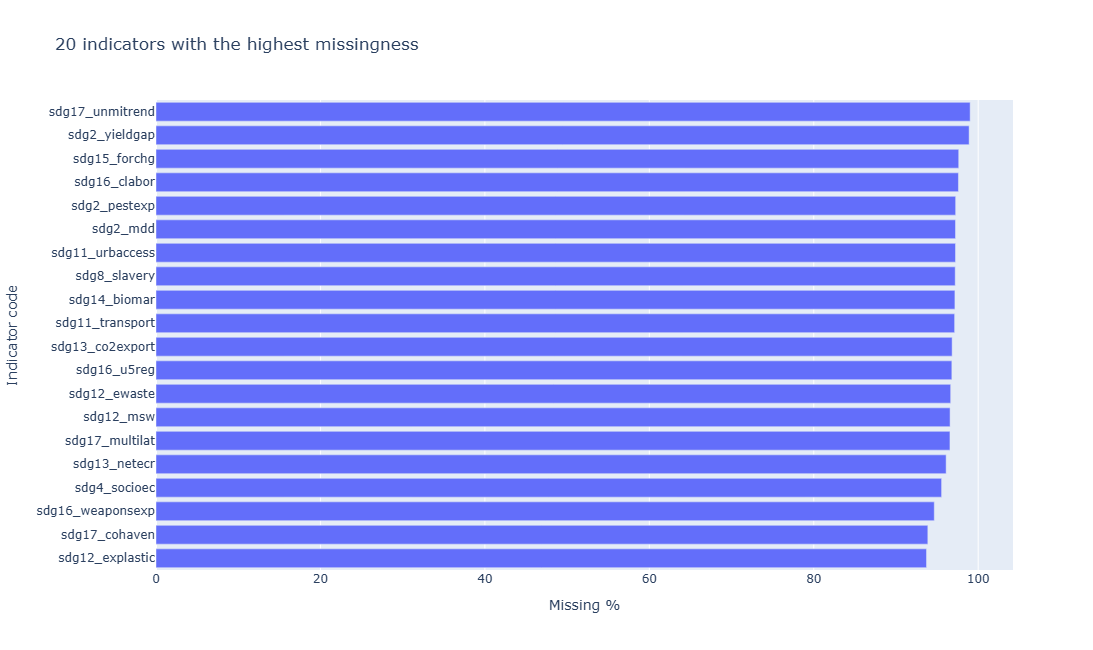

Indicator columns: 124
Missingness across all country-year-indicator cells: 54.5%


In [9]:
indicator_cols = [c for c in raw.columns if re.match(r"^sdg\d+_", str(c))]
missing = raw[indicator_cols].isna().mean().mul(100).sort_values(ascending=False)
missing_df = missing.head(20).rename("Missing %").reset_index().rename(columns={"index":"Indicator code"})
fig = px.bar(missing_df.sort_values("Missing %"), x="Missing %", y="Indicator code", orientation="h",
             title="20 indicators with the highest missingness")
fig.update_layout(height=650)
fig.show()
print(f"Indicator columns: {len(indicator_cols)}")
print(f"Missingness across all country-year-indicator cells: {raw[indicator_cols].isna().mean().mean()*100:.1f}%")

## 6. Goal dashboard statuses

,Goal,Status,Trend
0,SDG 1,yellow,↑
1,SDG 2,red,→
2,SDG 3,red,➚
3,SDG 4,yellow,➚
4,SDG 5,red,➚
5,SDG 6,orange,➚
6,SDG 7,orange,➚
7,SDG 8,orange,➚
8,SDG 9,orange,➚
9,SDG 10,green,NaN


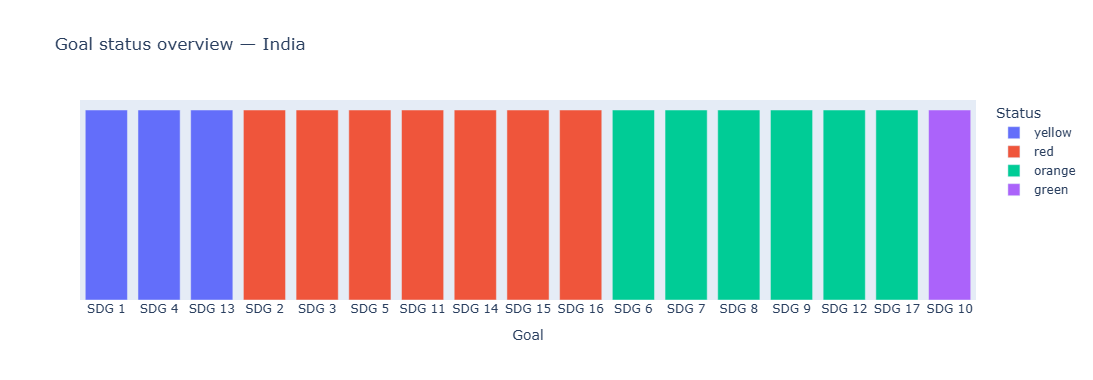

In [10]:
country = "India"
row = overview.loc[overview["country"].eq(country)]
goal_rows = []
for g in range(1, 18):
    dc, tc = f"Goal {g} Dash", f"Goal {g} Trend"
    if dc in overview.columns and len(row):
        goal_rows.append({"Goal": f"SDG {g}", "Status": row[dc].iloc[0],
                          "Trend": row[tc].iloc[0] if tc in overview.columns else "Unknown"})
goal_df = pd.DataFrame(goal_rows)
display(goal_df)
if not goal_df.empty:
    fig = px.bar(goal_df, x="Goal", y=[1]*len(goal_df), color="Status",
                 hover_data=["Trend"], title=f"Goal status overview — {country}")
    fig.update_layout(yaxis={"visible": False}, height=380)
    fig.show()

## Interpretation cautions
- The raw indicator table has substantial missingness; do not treat missing values as zero.
- Different indicators have different units and directions. A higher raw value is not always better.
- Historical SDG index values are retrospectively calculated and may use carried-forward observations.
- This analysis is descriptive and does not establish causal relationships.